# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/09-Au


# Database loading and quick analysis

In [3]:
# data=pd.read_csv("SiComplete-2021-08-25-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_au          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [4]:
data=datafull
# data=data[data.Functional==IndexFunctional["GGA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_VperM,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,9888858.0,20200510.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,5.996342e+09,0.0,0.0,0.0,1.0,0.0,4000.00,0.000000
1,9888861.0,20200518.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,-1.390726e+08,0.0,0.0,0.0,1.0,0.0,787.50,0.000000
2,9910547.0,20200519.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,1.979937e+09,0.0,0.0,0.0,1.0,0.0,800.00,0.000000
3,9894833.0,20200521.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,2.251518e+10,0.0,0.0,0.0,1.0,0.0,1025.00,0.000000
4,10206993.0,20201029.0,24.0,0.377945,4.000000e-07,3.000000e-14,1.000000e+07,0.0,0.0,4.000000e-07,...,0.000000,0.000029,2.883668e+13,0.0,0.0,0.0,1.0,0.0,6094.50,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
429,9679604.0,20191204.0,16.0,0.434637,8.000000e-07,3.000000e-14,1.000000e+09,0.0,0.0,8.000000e-07,...,0.000000,0.051726,1.420134e+14,0.0,0.0,0.0,3.0,2.0,6073.75,0.000000
430,9679615.0,20191204.0,16.0,0.434637,8.000000e-07,3.000000e-14,5.000000e+10,0.0,0.0,8.000000e-07,...,33.515537,3948.238560,-2.976771e+15,0.0,0.0,0.0,3.0,2.0,3875.00,1350.561231
431,9679607.0,20191204.0,16.0,0.434637,8.000000e-07,3.000000e-14,5.000000e+09,0.0,0.0,8.000000e-07,...,0.571618,2.292344,1.034320e+15,0.0,0.0,0.0,3.0,2.0,5500.00,1350.561231
432,9678344.0,20191203.0,16.0,0.434637,8.000000e-07,3.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,4.800368,32.629169,1.858972e+15,0.0,0.0,0.0,3.0,2.0,4875.00,1350.561231


In [5]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==1]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_VperM,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,9888858.0,20200510.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,5.996342e+09,0.0,0.0,0.0,1.0,0.0,4000.00,0.000000
1,9888861.0,20200518.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,-1.390726e+08,0.0,0.0,0.0,1.0,0.0,787.50,0.000000
2,9910547.0,20200519.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,1.979937e+09,0.0,0.0,0.0,1.0,0.0,800.00,0.000000
3,9894833.0,20200521.0,24.0,0.377945,8.000000e-07,2.000000e-14,0.000000e+00,0.0,0.0,8.000000e-07,...,0.000000,0.000000,2.251518e+10,0.0,0.0,0.0,1.0,0.0,1025.00,0.000000
6,9769349.0,20200207.0,24.0,0.377945,8.000000e-07,3.000000e-14,1.500000e+12,0.0,0.0,8.000000e-07,...,20.959679,1195.494350,-4.229460e+15,0.0,0.0,0.0,1.0,0.0,4000.00,2480.482490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,9681903.0,20191205.0,16.0,0.340151,8.000000e-07,3.000000e-14,1.000000e+09,0.0,0.0,8.000000e-07,...,0.000118,0.000407,-2.894575e+10,0.0,0.0,0.0,3.0,2.0,3875.00,1350.561231
412,9679612.0,20191205.0,16.0,0.340151,8.000000e-07,3.000000e-14,5.000000e+10,0.0,0.0,8.000000e-07,...,0.142890,1.026254,1.502054e+14,0.0,0.0,0.0,3.0,2.0,3375.00,1350.561231
413,9681940.0,20191205.0,16.0,0.340151,8.000000e-07,3.000000e-14,5.000000e+11,0.0,0.0,8.000000e-07,...,6.883042,137.410579,-3.602123e+15,0.0,0.0,0.0,3.0,2.0,2625.00,1350.561231
415,9681912.0,20191205.0,16.0,0.340151,8.000000e-07,3.000000e-14,5.000000e+09,0.0,0.0,8.000000e-07,...,0.004898,0.010993,9.013205e+11,0.0,0.0,0.0,3.0,2.0,3750.00,1350.561231


In [6]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [7]:
datafull

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_VperM,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
132,10211478.0,20201103.0,24.0,0.377945,2.490000e-07,3.000000e-14,1.000000e+08,0.0,0.0,2.490000e-07,...,0.000000,0.000194,-1.267523e+11,0.0,0.0,0.0,1.0,0.0,6094.5,0.00000
119,10211479.0,20201103.0,24.0,0.377945,2.490000e-07,3.000000e-14,2.000000e+08,0.0,0.0,2.490000e-07,...,0.000000,0.000780,-2.766156e+11,0.0,0.0,0.0,1.0,0.0,6094.5,0.00000
278,10211480.0,20201103.0,24.0,0.377945,2.490000e-07,3.000000e-14,3.000000e+08,0.0,0.0,2.490000e-07,...,0.000000,0.001760,-4.080326e+11,0.0,0.0,0.0,1.0,0.0,6094.5,0.00000
125,10211481.0,20201103.0,24.0,0.377945,2.490000e-07,3.000000e-14,4.000000e+08,0.0,0.0,2.490000e-07,...,0.000000,0.003139,-5.442424e+11,0.0,0.0,0.0,1.0,0.0,6094.5,0.00000
90,10211482.0,20201103.0,24.0,0.377945,2.490000e-07,3.000000e-14,5.000000e+08,0.0,0.0,2.490000e-07,...,0.000000,0.004923,-6.782355e+11,0.0,0.0,0.0,1.0,0.0,6094.5,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,9825746.0,20200319.0,24.0,0.377945,8.000000e-07,6.000000e-14,9.000000e+11,0.0,0.0,8.000000e-07,...,17.611209,803.750298,-3.121692e+15,0.0,0.0,0.0,1.0,0.0,7750.0,4960.96498
181,9916300.0,20200521.0,24.0,0.377945,8.000000e-07,6.000000e-14,9.000000e+11,0.0,0.0,8.000000e-07,...,0.000000,620.557471,5.988995e+15,0.0,0.0,0.0,1.0,0.0,6937.5,4960.96498
149,9825747.0,20200319.0,24.0,0.377945,8.000000e-07,6.000000e-14,1.000000e+12,0.0,0.0,8.000000e-07,...,18.779791,987.707826,4.947754e+15,0.0,0.0,0.0,1.0,0.0,7625.0,4960.96498
162,9825748.0,20200319.0,24.0,0.377945,8.000000e-07,6.000000e-14,2.000000e+12,0.0,0.0,8.000000e-07,...,23.977348,3173.824766,1.994761e+15,0.0,0.0,0.0,1.0,0.0,7000.0,4960.96498


In [15]:
datalocal=datafull
print("Wavelengths: ", set(datalocal.lambda1), "\nPulse durations: ", set(datalocal.tau1), "\nPulse type: ", set(datalocal.STH))
print("Mesh: ", set(datalocal.realmesh), "\nInduced fields: ", set(datalocal.InducedFields), "\nFunctional: ", set(datalocal.Functional))
print("MoveIon: ", set(datalocal.MoveIon), "Frozen Hxc: ", set(datalocal.FrozenHxc))

Wavelengths:  {8e-07, 2.4899999999999997e-07} 
Pulse durations:  {2e-14, 6e-14, 3e-14} 
Pulse type:  {1.0, 3.0}
Mesh:  {0.377945225092, 0.340150702582} 
Induced fields:  {1.0} 
Functional:  {2.0}
MoveIon:  {0.0} Frozen Hxc:  {0.0, 1.0}


In [18]:
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda2-1.367968e-6/2.)<1e-9]
# datatmp=datatmp[np.fabs(datatmp.lambda1-800E-9)<1e-9] #Wavelength selection
# datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1e-15] #Pulse duration selection
datatmp=datatmp[datatmp.Efield2==0]
# datatmp=datatmp[datatmp.Efield1<3E11]
# datatmp=datatmp[datatmp.Efield1>3E10]
# datatmp=datatmp[datatmp.CEP1==0]
# datatmp=datatmp[datatmp.STH==1]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[np.fabs(datatmp.tau1-13.94e-15)<1E-15]
datatmp=datatmp[datatmp.PolarizationAngle==0]
datatmp=datatmp[datatmp.ProbeFieldAmplitude_au>0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

In [19]:
datalocal=data2
print("Wavelengths: ", set(datalocal.lambda1), "\nPulse durations: ", set(datalocal.tau1), "\nPulse type: ", set(datalocal.STH))
print("Mesh: ", set(datalocal.realmesh), "\nInduced fields: ", set(datalocal.InducedFields), "\nFunctional: ", set(datalocal.Functional))
print("MoveIon: ", set(datalocal.MoveIon), "Frozen Hxc: ", set(datalocal.FrozenHxc))
datatmp

Wavelengths:  set() 
Pulse durations:  set() 
Pulse type:  set()
Mesh:  set() 
Induced fields:  set() 
Functional:  set()
MoveIon:  set() Frozen Hxc:  set()


,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_VperM,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime


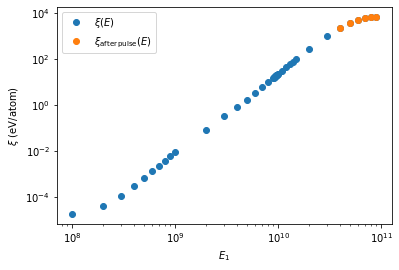

In [75]:
plt.figure()
plt.loglog(data2.Efield1, data2.Energy_eV, "o", label=r"$\xi(E)$")
plt.loglog(data2.Efield1, data2.Energy_afterpulse_eV, "o", label=r"$\xi_{\mathrm{after\,pulse}}(E)$")
plt.xlabel(r"$E_1$")
plt.ylabel(r"$\xi$ (eV/atom)")
plt.legend()